In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

df = pd.read_csv("airline-passengers.csv")

print(df.head())
print(df.shape)

     Month  Passengers
0  1949-01         112
1  1949-02         118
2  1949-03         132
3  1949-04         129
4  1949-05         121
(144, 2)


Month         datetime64[us]
Passengers             int64
dtype: object


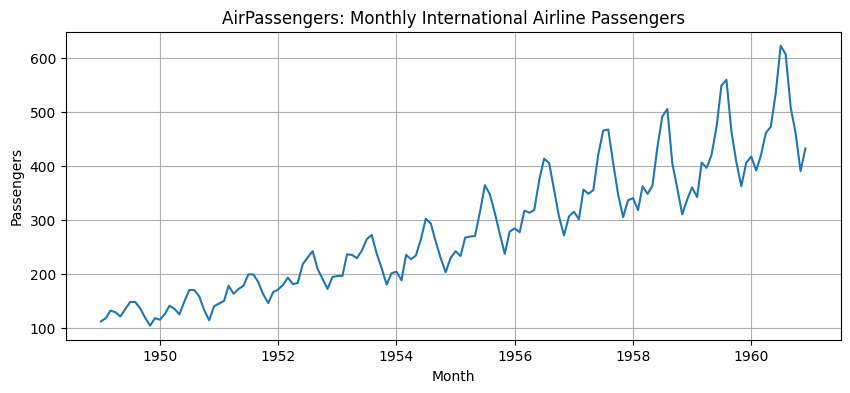

In [4]:
df["Month"] = pd.to_datetime(df["Month"])

print(df.dtypes)

plt.figure(figsize=(10, 4))
plt.plot(df["Month"], df["Passengers"])
plt.xlabel("Month")
plt.ylabel("Passengers")
plt.title("AirPassengers: Monthly International Airline Passengers")
plt.grid(True)
plt.show()

In [5]:
df["lag_1"] = df["Passengers"].shift(1)
df["lag_2"] = df["Passengers"].shift(2)
df["lag_3"] = df["Passengers"].shift(3)

print(df.head(6))

       Month  Passengers  lag_1  lag_2  lag_3
0 1949-01-01         112    NaN    NaN    NaN
1 1949-02-01         118  112.0    NaN    NaN
2 1949-03-01         132  118.0  112.0    NaN
3 1949-04-01         129  132.0  118.0  112.0
4 1949-05-01         121  129.0  132.0  118.0
5 1949-06-01         135  121.0  129.0  132.0


In [6]:
df = df.dropna().reset_index(drop=True)
print(df.head())

       Month  Passengers  lag_1  lag_2  lag_3
0 1949-04-01         129  132.0  118.0  112.0
1 1949-05-01         121  129.0  132.0  118.0
2 1949-06-01         135  121.0  129.0  132.0
3 1949-07-01         148  135.0  121.0  129.0
4 1949-08-01         148  148.0  135.0  121.0


In [8]:
df["month_num"] = df["Month"].dt.month
df["year"] = df["Month"].dt.year

print(df[["Month", "Passengers", "lag_1", "lag_2", "lag_3", "month_num", "year"]].head())

       Month  Passengers  lag_1  lag_2  lag_3  month_num  year
0 1949-04-01         129  132.0  118.0  112.0          4  1949
1 1949-05-01         121  129.0  132.0  118.0          5  1949
2 1949-06-01         135  121.0  129.0  132.0          6  1949
3 1949-07-01         148  135.0  121.0  129.0          7  1949
4 1949-08-01         148  148.0  135.0  121.0          8  1949


In [9]:
X = df[["lag_1", "lag_2", "lag_3", "month_num", "year"]]
y = df["Passengers"]

print(X.head())
print(y.head())

   lag_1  lag_2  lag_3  month_num  year
0  132.0  118.0  112.0          4  1949
1  129.0  132.0  118.0          5  1949
2  121.0  129.0  132.0          6  1949
3  135.0  121.0  129.0          7  1949
4  148.0  135.0  121.0          8  1949
0    129
1    121
2    135
3    148
4    148
Name: Passengers, dtype: int64


In [10]:
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

dates_test = df["Month"].iloc[split_index:]

print("Train samples:", len(X_train))
print("Test samples:", len(X_test))

Train samples: 112
Test samples: 29


In [11]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

print("Intercept:", linear_model.intercept_)
print("Coefficients:", linear_model.coef_)

Intercept: -31315.95954831056
Coefficients: [ 1.10362002 -0.48263667 -0.14196435  2.99350574 16.08601154]


In [12]:
linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))

print("Linear Regression MAE:", linear_mae)
print("Linear Regression RMSE:", linear_rmse)

Linear Regression MAE: 33.366721816551006
Linear Regression RMSE: 39.189007992262916


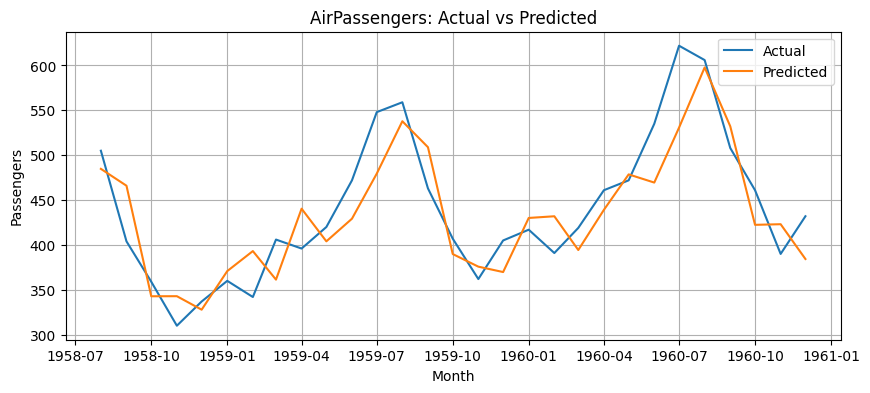

In [13]:
plt.figure(figsize=(10, 4))

plt.plot(dates_test, y_test.values, label="Actual")
plt.plot(dates_test, linear_pred, label="Predicted")

plt.xlabel("Month")
plt.ylabel("Passengers")
plt.title("AirPassengers: Actual vs Predicted")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)

Random Forest MAE: 48.203103448275854
Random Forest RMSE: 65.39722809954141


Original shape: (3650, 2)
         Date  Temp
0  1981-01-01  20.7
1  1981-01-02  17.9
2  1981-01-03  18.8
3  1981-01-04  14.6
4  1981-01-05  15.8
Missing values before handling:
 Date    0
Temp    0
dtype: int64


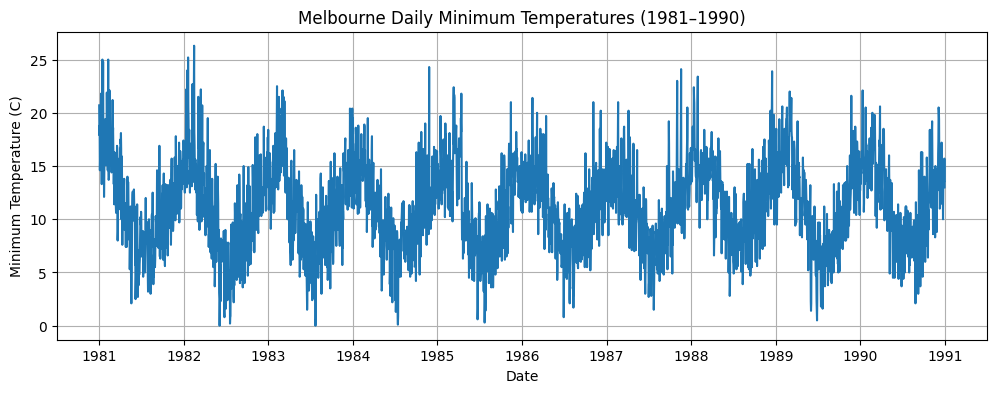

In [15]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
df = pd.read_csv(url)

print("Original shape:", df.shape)
print(df.head())

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print("Missing values before handling:\n", df.isnull().sum())

df = df.dropna(subset=["Temp"]).reset_index(drop=True)

plt.figure(figsize=(12, 4))
plt.plot(df["Date"], df["Temp"])
plt.xlabel("Date")
plt.ylabel("Minimum Temperature (C)")
plt.title("Melbourne Daily Minimum Temperatures (1981–1990)")
plt.grid(True)
plt.show()

In [16]:
df["lag_1"] = df["Temp"].shift(1)
df["lag_2"] = df["Temp"].shift(2)
df["lag_3"] = df["Temp"].shift(3)

df["month"] = df["Date"].dt.month

df = df.dropna().reset_index(drop=True)

print("Shape after lag creation:", df.shape)
print(df[["Date", "Temp", "lag_1", "lag_2", "lag_3", "month"]].head())

Shape after lag creation: (3647, 6)
        Date  Temp  lag_1  lag_2  lag_3  month
0 1981-01-04  14.6   18.8   17.9   20.7      1
1 1981-01-05  15.8   14.6   18.8   17.9      1
2 1981-01-06  15.8   15.8   14.6   18.8      1
3 1981-01-07  15.8   15.8   15.8   14.6      1
4 1981-01-08  17.4   15.8   15.8   15.8      1


Train samples: 2917
Test samples: 730
Linear Regression MAE:  1.8333
Linear Regression RMSE: 2.3167
Random Forest MAE:      1.7888
Random Forest RMSE:     2.2378


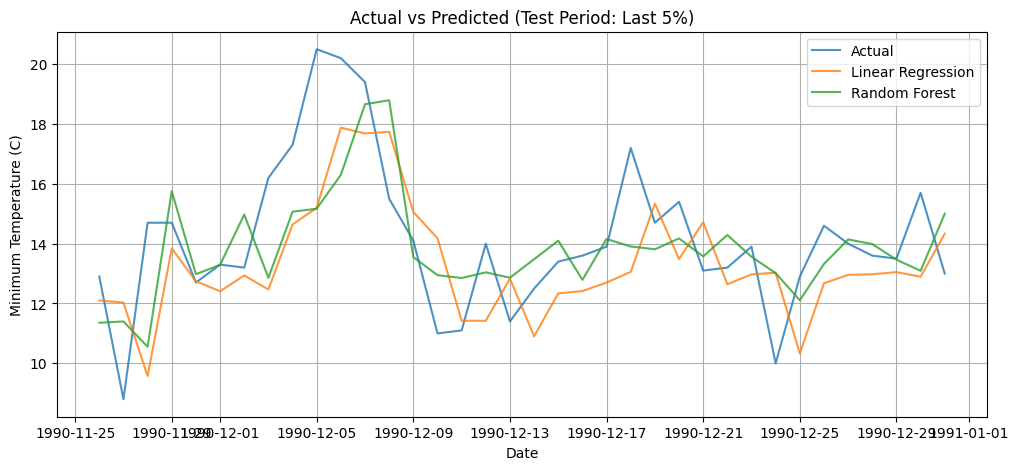

In [24]:
feature_cols = ["lag_1", "lag_2", "lag_3", "month"]
X = df[feature_cols]
y = df["Temp"]

split_index = int(len(df) * 0.8)
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]
dates_test = df["Date"].iloc[split_index:]

print("Train samples:", len(X_train))
print("Test samples:", len(X_test))

# Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))

print(f"Linear Regression MAE:  {linear_mae:.4f}")
print(f"Linear Regression RMSE: {linear_rmse:.4f}")

# Random Forest
rf_model = RandomForestRegressor(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

print(f"Random Forest MAE:      {rf_mae:.4f}")
print(f"Random Forest RMSE:     {rf_rmse:.4f}")

display_fraction = 0.05
n_display = max(1, int(len(X_test) * display_fraction))
display_dates = dates_test.iloc[-n_display:]

plt.figure(figsize=(12, 5))
plt.plot(display_dates, y_test.iloc[-n_display:].values, label="Actual", alpha=0.8)
plt.plot(display_dates, linear_pred[-n_display:], label="Linear Regression", alpha=0.8)
plt.plot(display_dates, rf_pred[-n_display:], label="Random Forest", alpha=0.8)
plt.xlabel("Date")
plt.ylabel("Minimum Temperature (C)")
plt.title(f"Actual vs Predicted (Test Period: Last {(display_fraction * 100):.0f}%)")
plt.legend()
plt.grid(True)
plt.show()